# From Entropy to SVI Notebook

Companion to the slides `VariationalInference.pdf`. Sections in slide order:
- **Entropy:** definition, simple examples, differential entropy of a Gaussian (slides 12, 15, 17)
- **Demo A1:** surprise, average surprise and perplexity (slides 13–14); summary table (slide 16)
- **KL divergence:** definition, cross-entropy identity, non-negativity (slides 18, 20)
- **KL order matters:** forward vs reverse KL on a bimodal target, with demos B3 and B4 (slides 21–23)
- **Variational distributions and mean-field:** Jensen, ELBO, correlated posterior vs mean-field (slides 24–29, 35; Jensen examples in appendix slides 55–56)
- **ELBO:** gap to the evidence, decomposition, landscape (slides 27–28)
- **The two gradient estimators:** reparameterization (pathwise) vs REINFORCE (score function), baselines (slides 38–44; appendix slides 57–58)
- **Black-box SVI recipe:** pathwise gradients, minibatches with $N/k$ scaling, Adam (slides 41–42, 44, 47)


## 1. Definition of Shannon Entropy

For a discrete random variable $X$ that can take values $x_1, \dots, x_n$ with probabilities
$p(x_i)$, the **Shannon entropy** (base 2) is defined as:

\begin{equation}
H(X) = - \sum_{i=1}^n p(x_i) \log_2 p(x_i).
\end{equation}

- We measure entropy in **bits** when we use $\log_2$.
- Entropy is **maximum** when the distribution is uniform.
- Entropy is **zero** when one outcome has probability 1 (no uncertainty).

In [ ]:
import math
from typing import Iterable

def entropy(probs: Iterable[float], base: float = 2.0) -> float:
    """Compute Shannon entropy of a discrete distribution.

    Args:
        probs: Iterable of probabilities that sum to 1.
        base: Logarithm base (2 for bits, math.e for nats, 10 for dits).

    Returns:
        Entropy in the chosen log base.
    """
    probs = list(probs)
    # Basic sanity check
    if any(p < 0 for p in probs):
        raise ValueError("Probabilities must be non-negative.")
    total = sum(probs)
    if not math.isclose(total, 1.0, rel_tol=1e-6, abs_tol=1e-6):
        raise ValueError(f"Probabilities must sum to 1 (got {total}).")

    # Compute entropy
    return -sum(p * math.log(p, base) for p in probs if p > 0.0)

entropy([0.5, 0.5])  # quick test; should be 1.0 bit

1.0

## 2. Simple Examples

Let's compute entropy for a few basic distributions.

In [ ]:
examples = {
    "Fair coin (0.5, 0.5)": [0.5, 0.5],
    "Biased coin (0.9, 0.1)": [0.9, 0.1],
    "Fair 4-sided die": [0.25] * 4,
    "Fair 6-sided die": [1/6] * 6,
    "Non-uniform 3-outcome (0.5, 0.25, 0.25)": [0.5, 0.25, 0.25],
}

for name, probs in examples.items():
    h = entropy(probs)
    print(f"{name:35s} -> H = {h:.4f} bits")

Fair coin (0.5, 0.5)                -> H = 1.0000 bits
Biased coin (0.9, 0.1)              -> H = 0.4690 bits
Fair 4-sided die                    -> H = 2.0000 bits
Fair 6-sided die                    -> H = 2.5850 bits
Non-uniform 3-outcome (0.5, 0.25, 0.25) -> H = 1.5000 bits



## 3. Differential entropy (Gaussian)

For $X\sim\mathcal{N}(0,\sigma^2)$:
$h(X)=\tfrac12\log(2\pi e\sigma^2).$
Bigger $\sigma$ → more spread → higher differential entropy.


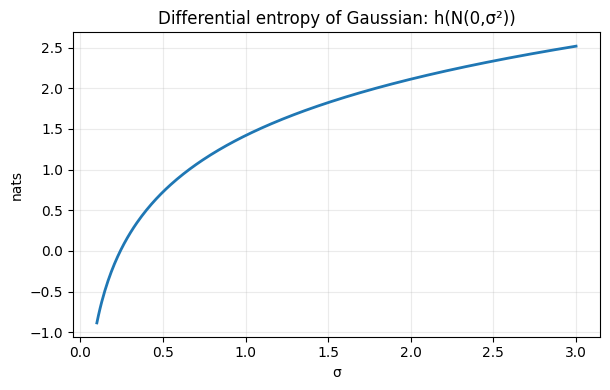

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('vi_entropy_kl_assets/figures', exist_ok=True)

sig = np.linspace(0.1, 3.0, 300)
h = 0.5*np.log(2*np.pi*np.e*sig**2)

plt.figure(figsize=(6.2,4))
plt.plot(sig, h, lw=2)
plt.title('Differential entropy of Gaussian: h(N(0,σ²))')
plt.xlabel('σ')
plt.ylabel('nats')
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig('vi_entropy_kl_assets/figures/gaussian_differential_entropy.png')
plt.show()


# Part A+ — Building intuition for entropy (interactive)

The demo below is about **feeling** what entropy measures:

| Demo | Idea | ML connection |
|---|---|---|
| A1 | Entropy = **average surprise**; perplexity $2^H$ | log-loss, anomaly scores, LLM perplexity |

**How to use:** run the setup cell once, then run the demo cell and drag the sliders. The demo ends with a few *"Try this"* prompts.


In [ ]:
# ===================== Setup for the interactive demos =====================
# Works in Colab / Jupyter. If ipywidgets is missing, every demo renders once
# with its default values instead of showing sliders.
import heapq
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

try:
    import ipywidgets as widgets
    from ipywidgets import (interact, FloatSlider, IntSlider, FloatLogSlider,
                            Dropdown, SelectionSlider)
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets not found -> demos render once with default values "
          "(pip install ipywidgets to get sliders).")

    class _StaticControl:
        def __init__(self, value=None, options=None, **kwargs):
            if value is None and options is not None:
                value = list(options)[0]
            self.value = value
    FloatSlider = IntSlider = FloatLogSlider = Dropdown = SelectionSlider = _StaticControl


def live(func, **controls):
    """Attach slider controls to `func` (or call it once without ipywidgets)."""
    if HAVE_WIDGETS:
        return interact(func, **controls)
    return func(**{k: getattr(c, 'value', c) for k, c in controls.items()})


def slider(lo, hi, step, value, desc, cont=True):
    return FloatSlider(min=lo, max=hi, step=step, value=value, description=desc,
                       continuous_update=cont, style={'description_width': 'initial'})


# ---- information-theory helpers (numpy versions; base 2 = bits) ----
def H_bits(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def CE_bits(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    m = p > 0
    return np.inf if np.any(q[m] == 0) else float(-(p[m] * np.log2(q[m])).sum())

def KL_bits(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    m = p > 0
    return np.inf if np.any(q[m] == 0) else float((p[m] * np.log2(p[m] / q[m])).sum())

def softmax(z, T=1.0):
    z = np.asarray(z, float) / T
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

def normalize(w):
    w = np.clip(np.asarray(w, float), 0, None)
    return w / w.sum() if w.sum() > 0 else np.ones_like(w) / len(w)

def gauss_pdf(x, m, s):
    return np.exp(-0.5 * ((x - m) / s)**2) / (np.sqrt(2 * np.pi) * s)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def binary_entropy(p):
    """Elementwise entropy (bits) of Bernoulli(p); works on arrays."""
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

# consistent colours: blue = "truth / P", orange = "model / Q", aqua = third series
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})
print("Setup done. Widgets:", HAVE_WIDGETS)

Setup done. Widgets: True


## A1. Surprise: the building block of entropy

The **surprise** (self-information) of an outcome is
$$ s(x) = -\log_2 p(x) \quad \text{[bits]} .$$

* $p=1 \Rightarrow s=0$: a certain event tells you nothing.
* $p=1/2 \Rightarrow s=1$ bit, $\;p=1/1024 \Rightarrow s=10$ bits: rare events are very surprising.

**Entropy is the average surprise:** $H(X)=\mathbb{E}[s(X)] = \sum_x p(x)\,(-\log_2 p(x))$.

Below: a weather forecaster's distribution over tomorrow's weather. The right panel shows the **contribution** $p(x)\,s(x)$ of each outcome to $H$: a very rare outcome is extremely surprising, *but it rarely happens*, so it contributes little.

**Perplexity** $2^{H}$ = "the distribution is as uncertain as a fair die with $2^H$ faces" (effective number of outcomes).

In [ ]:
WEATHER = ['sun', 'cloud', 'rain', 'snow']

def surprise_demo(w_sun=6.0, w_cloud=2.0, w_rain=1.5, w_snow=0.5):
    p = normalize([w_sun, w_cloud, w_rain, w_snow])
    s = -np.log2(np.clip(p, 1e-12, None))
    contrib = p * s
    H, K = H_bits(p), len(p)

    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
    ax[0].bar(WEATHER, p, color=C_BLUE)
    for i, v in enumerate(p):
        ax[0].text(i, v + 0.02, f'{v:.2f}', ha='center')
    ax[0].set_ylim(0, 1.1); ax[0].set_title('probability  p(x)')

    ax[1].bar(WEATHER, np.minimum(s, 15), color=C_ORANGE)
    for i, v in enumerate(s):
        ax[1].text(i, min(v, 15) + 0.2, '∞' if v > 30 else f'{v:.1f}', ha='center')
    ax[1].axhline(H, color='k', ls='--', lw=1.5, label=f'average = H = {H:.2f}')
    ax[1].set_ylim(0, max(4, min(s.max(), 15) * 1.2)); ax[1].legend(loc='upper left')
    ax[1].set_title('surprise  −log₂ p(x)  [bits]')

    bottom = 0
    for i, c in enumerate(contrib):
        ax[2].bar(['H'], [c], bottom=bottom, color=[C_BLUE, C_AQUA, C_ORANGE, C_GRAY][i],
                  edgecolor='white', linewidth=2, label=f'{WEATHER[i]}: {c:.2f}')
        bottom += c
    ax[2].axhline(np.log2(K), color='k', ls=':', label=f'max = log₂{K} = {np.log2(K):.0f}')
    ax[2].set_ylim(0, np.log2(K) * 1.6); ax[2].legend(fontsize=7, loc='upper center', ncol=2)
    ax[2].set_title('contribution  p(x)·s(x)')
    fig.suptitle(f'H = {H:.3f} bits    perplexity 2^H = {2**H:.2f} "effective outcomes" (out of {K})')
    plt.tight_layout(); plt.show()

live(surprise_demo,
     w_sun=slider(0, 10, 0.1, 6.0, 'weight sun'),
     w_cloud=slider(0, 10, 0.1, 2.0, 'weight cloud'),
     w_rain=slider(0, 10, 0.1, 1.5, 'weight rain'),
     w_snow=slider(0, 10, 0.1, 0.5, 'weight snow'))

interactive(children=(FloatSlider(value=6.0, description='weight sun', max=10.0, style=SliderStyle(description…

<function __main__.surprise_demo(w_sun=6.0, w_cloud=2.0, w_rain=1.5, w_snow=0.5)>

**Try this**
1. Set all weights equal → $H=\log_2 4 = 2$ bits, perplexity 4.
2. Make *snow* tiny (0.05). Its surprise explodes, but its contribution to $H$ goes **down** ($p\log p \to 0$).
3. Put almost all mass on *sun*. Which forecaster would you rather be scored against with log-loss: the confident one or the uniform one? (Log-loss = surprise of what actually happened. See KL section.)

> **ML link.** The log-loss / NLL used to train classifiers is exactly the surprise $-\log q(y)$ of the true label under the model. Anomaly detectors often flag inputs with high surprise $-\log p(x)$.

### Summary: what entropy tells you (as used in this lecture)

| Where | Quantity | What it measures |
|---|---|---|
| Classification loss | $-\log q(y)$ (surprise) | how surprised the model is by the true label |
| LLMs | perplexity $2^{H}$ | effective number of next-token choices |
| Max-entropy principle | $\arg\max H$ s.t. constraints | Gaussian for a fixed variance, uniform for a fixed support |
| VI / ELBO | $+H[q]$ term | stops $q$ collapsing to a point |


# KL Divergence Exploration

Use this part to:
- Compute KL divergence between discrete distributions
- Verify the relationship between KL divergence, entropy, and cross-entropy
- Check numerically that KL is non-negative


## 1. Definition of KL Divergence (Discrete Case)

Let $P$ and $Q$ be two discrete probability distributions on the same support $\{x_1, \dots, x_n\}$, with probabilities $p_i = P(x_i)$ and $q_i = Q(x_i)$.

The **Kullback--Leibler divergence** from $Q$ to $P$ is defined as
\begin{equation}
\mathrm{KL}(P \Vert Q) = \sum_{i=1}^n p_i \log \frac{p_i}{q_i}.
\end{equation}

- KL divergence is **not symmetric**: in general, $\mathrm{KL}(P\Vert Q) \neq \mathrm{KL}(Q\Vert P)$.
- KL is always **non-negative** and equals 0 if and only if $P = Q$ (same distribution).
- Intuitively, $\mathrm{KL}(P\Vert Q)$ measures how "wasteful" it is to use $Q$ as a model when the true distribution is $P$.

In [ ]:
import math
from typing import Iterable

def kl_divergence(P: Iterable[float], Q: Iterable[float], base: float = 2.0) -> float:
    """Compute KL(P || Q) for discrete distributions.

    Args:
        P: Iterable of probabilities for the true distribution P.
        Q: Iterable of probabilities for the model distribution Q.
        base: Logarithm base (2 for bits).

    Returns:
        KL divergence KL(P || Q) in the chosen log base.
    """
    P = list(P)
    Q = list(Q)
    if len(P) != len(Q):
        raise ValueError("P and Q must have the same length.")

    if any(p < 0 for p in P) or any(q < 0 for q in Q):
        raise ValueError("Probabilities must be non-negative.")

    if not math.isclose(sum(P), 1.0, rel_tol=1e-6, abs_tol=1e-6):
        raise ValueError(f"P must sum to 1 (got {sum(P)}).")
    if not math.isclose(sum(Q), 1.0, rel_tol=1e-6, abs_tol=1e-6):
        raise ValueError(f"Q must sum to 1 (got {sum(Q)}).")

    kl = 0.0
    for p, q in zip(P, Q):
        if p == 0.0:
            continue  # 0 * log(0/q) treated as 0
        if q == 0.0:
            raise ValueError("KL divergence is infinite when Q assigns zero probability to an event with p>0.")
        kl += p * math.log(p / q, base)
    return kl

# Quick sanity check
P = [0.5, 0.5]
Q = [0.5, 0.5]
kl_divergence(P, Q)

0.0

## 2. KL, Entropy, and Cross-Entropy

For discrete $P$ and $Q$ on the same support:
\begin{align}
H(P) &= -\sum_i p_i \log p_i, \\
H(P, Q) &= -\sum_i p_i \log q_i \quad \text{(cross-entropy)}, \\
\mathrm{KL}(P \Vert Q) &= H(P, Q) - H(P).
\end{align}

Below we implement entropy and cross-entropy, and verify the identity numerically.

In [ ]:
def entropy(P, base: float = 2.0) -> float:
    P = list(P)
    if any(p < 0 for p in P):
        raise ValueError("Probabilities must be non-negative.")
    if not math.isclose(sum(P), 1.0, rel_tol=1e-6, abs_tol=1e-6):
        raise ValueError(f"P must sum to 1 (got {sum(P)}).")
    return -sum(p * math.log(p, base) for p in P if p > 0.0)

def cross_entropy(P, Q, base: float = 2.0) -> float:
    P = list(P)
    Q = list(Q)
    if len(P) != len(Q):
        raise ValueError("P and Q must have same length.")
    return -sum(p * math.log(q, base) for p, q in zip(P, Q) if p > 0.0 and q > 0.0)

P = [0.6, 0.3, 0.1]
Q = [0.5, 0.25, 0.25]
H_P = entropy(P)
H_PQ = cross_entropy(P, Q)
KL_PQ = kl_divergence(P, Q)

print(f"H(P)      = {H_P:.4f} bits")
print(f"H(P, Q)   = {H_PQ:.4f} bits")
print(f"KL(P||Q)  = {KL_PQ:.4f} bits")
print(f"H(P,Q) - H(P) = {H_PQ - H_P:.4f} bits")

H(P)      = 1.2955 bits
H(P, Q)   = 1.4000 bits
KL(P||Q)  = 0.1045 bits
H(P,Q) - H(P) = 0.1045 bits


## 3. Numerical Check: KL is Non-Negative

We can sample random distributions $P$ and $Q$ and check that $\mathrm{KL}(P\Vert Q) \ge 0$.


In [ ]:
import random

def random_distribution(n: int):
    xs = [random.random() for _ in range(n)]
    s = sum(xs)
    return [x / s for x in xs]

for n in [2, 3, 5]:
    print(f"n = {n}")
    for _ in range(5):
        P = random_distribution(n)
        Q = random_distribution(n)
        kl = kl_divergence(P, Q)
        print(f"  KL(P||Q) = {kl:.6f}")
    print()

n = 2
  KL(P||Q) = 0.795107
  KL(P||Q) = 0.407170
  KL(P||Q) = 0.022638
  KL(P||Q) = 0.000246
  KL(P||Q) = 1.045205

n = 3
  KL(P||Q) = 0.645993
  KL(P||Q) = 0.280765
  KL(P||Q) = 0.643680
  KL(P||Q) = 1.161579
  KL(P||Q) = 0.481585

n = 5
  KL(P||Q) = 1.002679
  KL(P||Q) = 0.959989
  KL(P||Q) = 0.186840
  KL(P||Q) = 1.112663
  KL(P||Q) = 0.647113




# KL Divergence: Order Matters (Corrected Demonstration)

A plotted example can make forward and reverse KL look similar. That happens because **KL objectives are non-convex** in the parameters of the approximation family. For a symmetric bimodal target and a unimodal Gaussian approximation, **reverse KL has multiple optima**:

- two **global** optima near each mode (mode-seeking)
- one **local** optimum near the center (looks mass-covering)

We'll reproduce this and compute KL values to verify which is truly best.




In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import torch

os.makedirs('vi_kl_assets_v2/figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 120



## 1) Setup: bimodal target p(x) and Gaussian q(x)

Target:
$p(x)=0.5\,\mathcal{N}(-2,0.5^2)+0.5\,\mathcal{N}(2,0.5^2).$
Approximation family:
$q(x)=\mathcal{N}(\mu,\sigma^2).$

We'll optimize:
- forward KL: $\mathrm{KL}(p\|q)=\mathbb{E}_p[\log p-\log q]$
- reverse KL: $\mathrm{KL}(q\|p)=\mathbb{E}_q[\log q-\log p]$


In [ ]:

locs = torch.tensor([-2.0, 2.0])
scale = torch.tensor([0.5, 0.5])


def log_normal(x, mu, sigma):
    return -0.5*torch.log(2*torch.pi*sigma**2) - 0.5*((x-mu)/sigma)**2

def log_p_mixture(x):
    comps = []
    for k in range(2):
        comps.append(log_normal(x, locs[k], scale[k]) + torch.log(torch.tensor(0.5)))
    return torch.logsumexp(torch.stack(comps, dim=0), dim=0)

def log_q_gauss(x, mu, log_sigma):
    return log_normal(x, mu, torch.exp(log_sigma))


def sample_p(S):
    mix = torch.bernoulli(torch.full((S,), 0.5))
    eps = torch.randn(S)
    return torch.where(mix>0, locs[1] + scale[1]*eps, locs[0] + scale[0]*eps)



## 2) Optimization: multiple initializations

Key point: reverse KL is **non-convex** here.
- Starting near the center often yields the **center local optimum**.
- Starting near a mode yields a **mode global optimum**.

We’ll run reverse KL from 3 different initial $\mu$ values.


In [ ]:


def optimize_reverse_kl(mu0=0.0, log_sigma0=0.0, steps=2000, lr=0.03, S=2048, seed=0):
    torch.manual_seed(seed)
    mu = torch.tensor(mu0, requires_grad=True)
    log_sigma = torch.tensor(log_sigma0, requires_grad=True)
    opt = torch.optim.Adam([mu, log_sigma], lr=lr)
    for _ in range(steps):
        eps = torch.randn(S)
        x = mu + torch.exp(log_sigma)*eps
        kl = torch.mean(log_q_gauss(x, mu, log_sigma) - log_p_mixture(x))
        opt.zero_grad(); kl.backward(); opt.step()
    return float(mu.detach()), float(torch.exp(log_sigma.detach())), float(kl.detach())


def optimize_forward_kl(mu0=0.0, log_sigma0=0.0, steps=2000, lr=0.03, S=2048, seed=0):
    torch.manual_seed(seed)
    mu = torch.tensor(mu0, requires_grad=True)
    log_sigma = torch.tensor(log_sigma0, requires_grad=True)
    opt = torch.optim.Adam([mu, log_sigma], lr=lr)
    for _ in range(steps):
        x = sample_p(S)
        kl = torch.mean(log_p_mixture(x) - log_q_gauss(x, mu, log_sigma))
        opt.zero_grad(); kl.backward(); opt.step()
    return float(mu.detach()), float(torch.exp(log_sigma.detach())), float(kl.detach())

rev_center = optimize_reverse_kl(mu0=0.0, log_sigma0=0.0, seed=1)
rev_mode_pos = optimize_reverse_kl(mu0=1.5, log_sigma0=-0.7, seed=2)
rev_mode_neg = optimize_reverse_kl(mu0=-1.5, log_sigma0=-0.7, seed=3)
forw = optimize_forward_kl(mu0=0.0, log_sigma0=0.0, seed=4)

print('Reverse KL from center init  :', rev_center)
print('Reverse KL from +mode init   :', rev_mode_pos)
print('Reverse KL from -mode init   :', rev_mode_neg)
print('Forward KL (any init)        :', forw)


Reverse KL from center init  : (-0.051251303404569626, 1.7684096097946167, 1.8410736322402954)
Reverse KL from +mode init   : (1.9857902526855469, 0.4919416904449463, 0.6928116083145142)
Reverse KL from -mode init   : (-2.008500099182129, 0.49830037355422974, 0.6946550607681274)
Forward KL (any init)        : (-0.01427842490375042, 2.0679216384887695, 0.7377361059188843)



## 3) Plot: forward KL optimum vs reverse KL (global + local)

We plot:
- forward KL solution (mass-covering)
- reverse KL global solutions (mode-seeking)
- reverse KL local solution (center)

Note the KL values: reverse KL globals should be **smaller** than the center local optimum.


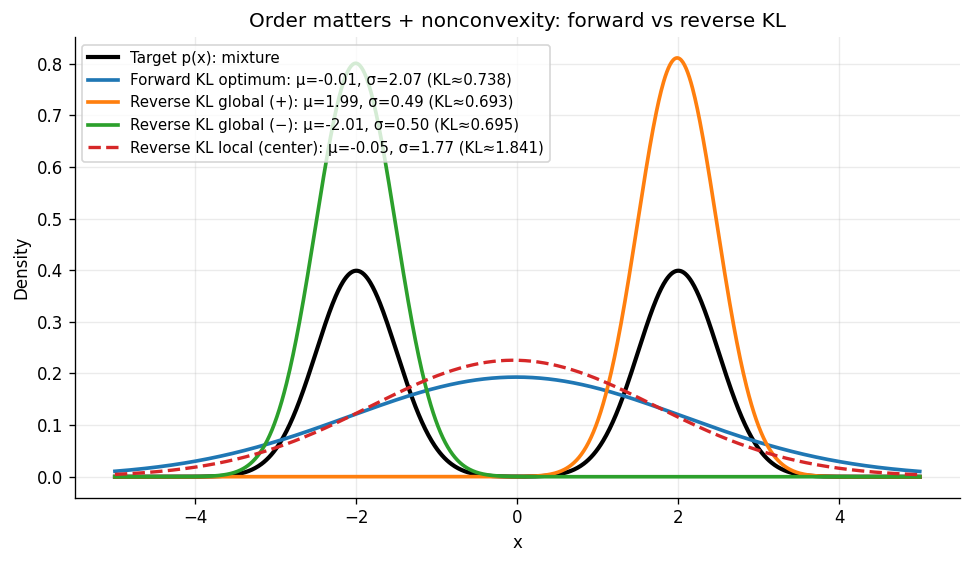

In [ ]:


def normal_pdf(x, mu, sigma):
    return 1/np.sqrt(2*np.pi*sigma**2) * np.exp(-0.5*((x-mu)/sigma)**2)

xs = np.linspace(-5, 5, 1000)
p_pdf = 0.5*normal_pdf(xs, -2, 0.5) + 0.5*normal_pdf(xs, 2, 0.5)

plt.figure(figsize=(8.2,4.8))
plt.plot(xs, p_pdf, 'k', lw=2.5, label='Target p(x): mixture')

mu, sig, kl = forw
plt.plot(xs, normal_pdf(xs, mu, sig), lw=2.2, label=f'Forward KL optimum: μ={mu:.2f}, σ={sig:.2f} (KL≈{kl:.3f})')

mu, sig, kl = rev_mode_pos
plt.plot(xs, normal_pdf(xs, mu, sig), lw=2.2, label=f'Reverse KL global (+): μ={mu:.2f}, σ={sig:.2f} (KL≈{kl:.3f})')

mu, sig, kl = rev_mode_neg
plt.plot(xs, normal_pdf(xs, mu, sig), lw=2.2, label=f'Reverse KL global (−): μ={mu:.2f}, σ={sig:.2f} (KL≈{kl:.3f})')

mu, sig, kl = rev_center
plt.plot(xs, normal_pdf(xs, mu, sig), lw=2.0, linestyle='--', label=f'Reverse KL local (center): μ={mu:.2f}, σ={sig:.2f} (KL≈{kl:.3f})')

plt.title('Order matters + nonconvexity: forward vs reverse KL')
plt.xlabel('x'); plt.ylabel('Density')
plt.grid(True, alpha=0.25)
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig('vi_kl_assets_v2/figures/forward_reverse_corrected.png')
plt.show()



## 4) Numerical check: compare KL values of candidate solutions

This confirms the main point:
- reverse KL **prefers a mode** (lower KL)
- the center solution is **only a local optimum**


In [ ]:

# Monte Carlo estimates of true KL values for the found solutions

rng = np.random.default_rng(0)

def log_p_np(x):
    a = np.log(0.5) + np.log(normal_pdf(x, -2, 0.5) + 1e-300)
    b = np.log(0.5) + np.log(normal_pdf(x,  2, 0.5) + 1e-300)
    m = np.maximum(a,b)
    return m + np.log(np.exp(a-m)+np.exp(b-m))

def log_q_np(x, mu, sig):
    return np.log(normal_pdf(x, mu, sig) + 1e-300)

def sample_p_np(S):
    mix = rng.random(S) < 0.5
    eps = rng.standard_normal(S)
    return np.where(mix, -2 + 0.5*eps, 2 + 0.5*eps)

def sample_q_np(S, mu, sig):
    return mu + sig*rng.standard_normal(S)

def kl_forward_np(mu, sig, S=200000):
    x = sample_p_np(S)
    return float(np.mean(log_p_np(x) - log_q_np(x, mu, sig)))

def kl_reverse_np(mu, sig, S=200000):
    x = sample_q_np(S, mu, sig)
    return float(np.mean(log_q_np(x, mu, sig) - log_p_np(x)))

cands = {
    'forward_opt': (forw[0], forw[1]),
    'reverse_global_plus': (rev_mode_pos[0], rev_mode_pos[1]),
    'reverse_global_minus': (rev_mode_neg[0], rev_mode_neg[1]),
    'reverse_local_center': (rev_center[0], rev_center[1]),
}

for name, (mu, sig) in cands.items():
    kf = kl_forward_np(mu, sig, S=120000)
    kr = kl_reverse_np(mu, sig, S=120000)
    print(f'{name:20s}  KL(p||q)≈{kf:8.3f}   KL(q||p)≈{kr:8.3f}')


forward_opt           KL(p||q)≈   0.722   KL(q||p)≈   2.108
reverse_global_plus   KL(p||q)≈  15.679   KL(q||p)≈   0.694
reverse_global_minus  KL(p||q)≈  15.413   KL(q||p)≈   0.693
reverse_local_center  KL(p||q)≈   0.752   KL(q||p)≈   1.887


# Part B+ — Building intuition for KL divergence (interactive)

| Demo | Reading of KL | ML connection |
|---|---|---|
| B3 | asymmetric penalty between Gaussians | VAE regulariser, VI variance under-estimation (slide 23) |
| B4 | forward vs reverse KL landscapes | VI (reverse) vs MLE / EP (forward) (slides 21–22) |

The setup cell is repeated so this part can be run on its own.

In [ ]:
# ===================== Setup for the interactive demos =====================
# Works in Colab / Jupyter. If ipywidgets is missing, every demo renders once
# with its default values instead of showing sliders.
import heapq
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

try:
    import ipywidgets as widgets
    from ipywidgets import (interact, FloatSlider, IntSlider, FloatLogSlider,
                            Dropdown, SelectionSlider)
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets not found -> demos render once with default values "
          "(pip install ipywidgets to get sliders).")

    class _StaticControl:
        def __init__(self, value=None, options=None, **kwargs):
            if value is None and options is not None:
                value = list(options)[0]
            self.value = value
    FloatSlider = IntSlider = FloatLogSlider = Dropdown = SelectionSlider = _StaticControl


def live(func, **controls):
    """Attach slider controls to `func` (or call it once without ipywidgets)."""
    if HAVE_WIDGETS:
        return interact(func, **controls)
    return func(**{k: getattr(c, 'value', c) for k, c in controls.items()})


def slider(lo, hi, step, value, desc, cont=True):
    return FloatSlider(min=lo, max=hi, step=step, value=value, description=desc,
                       continuous_update=cont, style={'description_width': 'initial'})


# ---- information-theory helpers (numpy versions; base 2 = bits) ----
def H_bits(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def CE_bits(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    m = p > 0
    return np.inf if np.any(q[m] == 0) else float(-(p[m] * np.log2(q[m])).sum())

def KL_bits(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    m = p > 0
    return np.inf if np.any(q[m] == 0) else float((p[m] * np.log2(p[m] / q[m])).sum())

def softmax(z, T=1.0):
    z = np.asarray(z, float) / T
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

def normalize(w):
    w = np.clip(np.asarray(w, float), 0, None)
    return w / w.sum() if w.sum() > 0 else np.ones_like(w) / len(w)

def gauss_pdf(x, m, s):
    return np.exp(-0.5 * ((x - m) / s)**2) / (np.sqrt(2 * np.pi) * s)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def binary_entropy(p):
    """Elementwise entropy (bits) of Bernoulli(p); works on arrays."""
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

# consistent colours: blue = "truth / P", orange = "model / Q", aqua = third series
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})
print("Setup done. Widgets:", HAVE_WIDGETS)

Setup done. Widgets: True


## B3. KL between Gaussians: asymmetric penalties (and the VAE regulariser)

$$
\mathrm{KL}\big(\mathcal N(\mu_1,\sigma_1^2)\,\|\,\mathcal N(\mu_2,\sigma_2^2)\big)=\log\frac{\sigma_2}{\sigma_1}+\frac{\sigma_1^2+(\mu_1-\mu_2)^2}{2\sigma_2^2}-\frac12 \quad\text{[nats]}.
$$
Fix the target $p=\mathcal N(0,1)$ and vary $q=\mathcal N(\mu,\sigma^2)$:

* **Reverse** $\mathrm{KL}(q\|p)$ (used in VI): a too-**wide** $q$ costs $\sim\sigma^2/2$ (fast), a too-**narrow** $q$ only $\sim-\log\sigma$ (slow) → VI tends to **under-estimate** variance.
* **Forward** $\mathrm{KL}(p\|q)$ (MLE, EP): too narrow costs $\sim 1/(2\sigma^2)$ (fast) → forward KL prefers to **over-cover**.
* With $p=\mathcal N(0,1)$ the reverse formula is $\tfrac12(\mu^2+\sigma^2-1-\log\sigma^2)$: precisely the **VAE KL term** that pulls each encoder output towards the prior.

In [ ]:
def kl_gauss_1d(m1, s1, m2, s2):
    """KL(N(m1,s1^2) || N(m2,s2^2)) in nats."""
    return np.log(s2 / s1) + (s1**2 + (m1 - m2)**2) / (2 * s2**2) - 0.5

def gauss_kl_demo(mu=0.0, sigma=0.5):
    xs = np.linspace(-5, 5, 500)
    sig_grid = np.linspace(0.15, 3, 300)
    fwd, rev = kl_gauss_1d(0, 1, mu, sigma), kl_gauss_1d(mu, sigma, 0, 1)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
    ax[0].plot(xs, gauss_pdf(xs, 0, 1), color=C_BLUE, lw=2, label='p = N(0,1)')
    ax[0].plot(xs, gauss_pdf(xs, mu, sigma), color=C_ORANGE, lw=2, label=f'q = N({mu:.1f}, {sigma:.2f}²)')
    ax[0].legend(); ax[0].set_title('densities')
    ax[1].plot(sig_grid, kl_gauss_1d(0, 1, mu, sig_grid), color=C_BLUE, lw=2, label='forward KL(p‖q)')
    ax[1].plot(sig_grid, kl_gauss_1d(mu, sig_grid, 0, 1), color=C_ORANGE, lw=2, label='reverse KL(q‖p)')
    ax[1].plot([sigma, sigma], [fwd, rev], 'o', color='k')
    ax[1].axvline(1, color=C_GRAY, ls=':')
    ax[1].set_ylim(0, 4); ax[1].set_xlabel('σ of q'); ax[1].set_ylabel('nats'); ax[1].legend()
    ax[1].set_title(f'at current μ = {mu:.1f}')
    fig.suptitle(f'KL(p‖q) = {fwd:.3f}   KL(q‖p) = {rev:.3f} nats')
    plt.tight_layout(); plt.show()

live(gauss_kl_demo, mu=slider(-3, 3, 0.1, 0.0, 'μ of q'), sigma=slider(0.15, 3, 0.01, 0.5, 'σ of q'))

interactive(children=(FloatSlider(value=0.0, description='μ of q', max=3.0, min=-3.0, style=SliderStyle(descri…

<function __main__.gauss_kl_demo(mu=0.0, sigma=0.5)>

## B4. Forward vs reverse KL on a bimodal target: the whole landscape

Same setting as the bimodal example above, $p=\tfrac12\mathcal N(-d,0.5^2)+\tfrac12\mathcal N(d,0.5^2)$, $q=\mathcal N(\mu,\sigma^2)$, but now you can **see both objective landscapes** over $(\mu,\sigma)$ and move $q$ around yourself (numerical integration on a grid).

* Forward KL: one basin, centred between the modes with a large $\sigma$ (**mass-covering**).
* Reverse KL: two basins, one per mode (**mode-seeking**), plus a saddle/local region in between.
* Shrink $d$: when modes overlap, the two behaviours merge.

In [ ]:
xg = np.linspace(-9, 9, 1201); dx = xg[1] - xg[0]

def log_mix(x, d, s=0.5):
    a = -0.5 * ((x + d) / s)**2; b = -0.5 * ((x - d) / s)**2
    return np.logaddexp(a, b) + np.log(0.5) - np.log(np.sqrt(2 * np.pi) * s)

def log_gauss(x, m, s):
    return -0.5 * ((x - m) / s)**2 - np.log(np.sqrt(2 * np.pi) * s)

def kl_pair(mu, sigma, d):
    """Return forward KL(p||q) and reverse KL(q||p), nats; mu, sigma may be arrays."""
    lp = log_mix(xg, d)
    lq = log_gauss(xg, np.asarray(mu)[..., None], np.asarray(sigma)[..., None])
    fwd = (np.exp(lp) * (lp - lq)).sum(-1) * dx
    rev = (np.exp(lq) * (lq - lp)).sum(-1) * dx
    return fwd, rev

MU_G, SIG_G = np.meshgrid(np.linspace(-4, 4, 81), np.linspace(0.2, 3.5, 56))

def landscape_demo(mu=0.0, sigma=1.0, d=2.0):
    F, R = kl_pair(MU_G, SIG_G, d)
    f, r = kl_pair(mu, sigma, d)
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), layout='constrained')
    ax[0].plot(xg, np.exp(log_mix(xg, d)), 'k', lw=2, label='p (target)')
    ax[0].plot(xg, np.exp(log_gauss(xg, mu, sigma)), color=C_ORANGE, lw=2, label='q')
    ax[0].set_xlim(-6, 6); ax[0].legend(); ax[0].set_title('densities')
    for a, Z, name, col in [(ax[1], F, 'forward KL(p‖q)', C_BLUE), (ax[2], R, 'reverse KL(q‖p)', C_ORANGE)]:
        cs = a.contourf(MU_G, SIG_G, np.clip(Z, 1e-3, 50), levels=np.logspace(-2, 1.7, 25),
                        norm=LogNorm(), cmap='viridis')
        i = np.unravel_index(np.argmin(Z), Z.shape)
        a.plot(MU_G[i], SIG_G[i], 'w*', ms=14, mec='k', label=f'min ≈ ({MU_G[i]:.1f}, {SIG_G[i]:.2f})')
        a.plot(mu, sigma, 'o', color=col, mec='white', ms=10, label='current q')
        a.set_xlabel('μ'); a.set_ylabel('σ'); a.set_title(name); a.legend(fontsize=7, loc='upper right')
        a.grid(False)
    fig.colorbar(cs, ax=ax[1:], label='KL [nats] (log colour)')
    fig.suptitle(f'current q:  KL(p‖q) = {float(f):.3f},   KL(q‖p) = {float(r):.3f} nats')
    plt.show()

live(landscape_demo, mu=slider(-4, 4, 0.1, 0.0, 'μ'), sigma=slider(0.2, 3.5, 0.05, 1.0, 'σ'),
     d=slider(0.0, 3.0, 0.1, 2.0, 'mode separation d', cont=False))

interactive(children=(FloatSlider(value=0.0, description='μ', max=4.0, min=-4.0, style=SliderStyle(description…

<function __main__.landscape_demo(mu=0.0, sigma=1.0, d=2.0)>


# Variational Distributions and Mean-Field Approximation

This notebook accompanies the slides. It provides:

- What a variational distribution $q(z)$ is and why we choose a tractable family
- Derivation of the ELBO using **Jensen's inequality**
- Mean-field factorization $q(z)=\prod_i q_i(z_i)$ and coordinate ascent intuition
- A 2D Gaussian example showing what mean-field cannot represent (correlations)

Figures are saved into `vi_mean_field_assets/figures/` for LaTeX inclusion.


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('vi_mean_field_assets/figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 120



## 1) Jensen's inequality (why we get a lower bound)

Because $\log$ is concave:
$ \log(\mathbb{E}[X]) \ge \mathbb{E}[\log X]. $

This is the key step in deriving the ELBO.


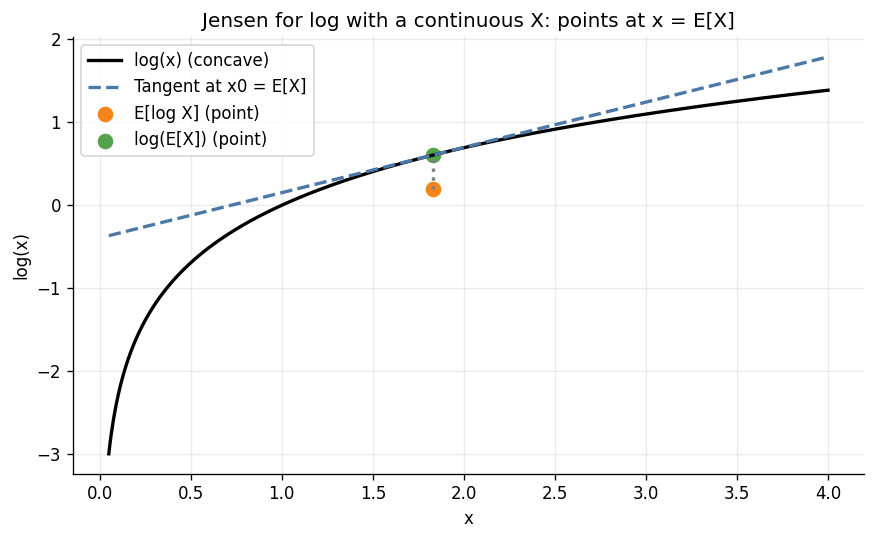

E[X]       = 1.8329274797875807
E[log X]   = 0.20011760799737363
log(E[X])  = 0.6059144044020087
gap        = 0.40579679640463506


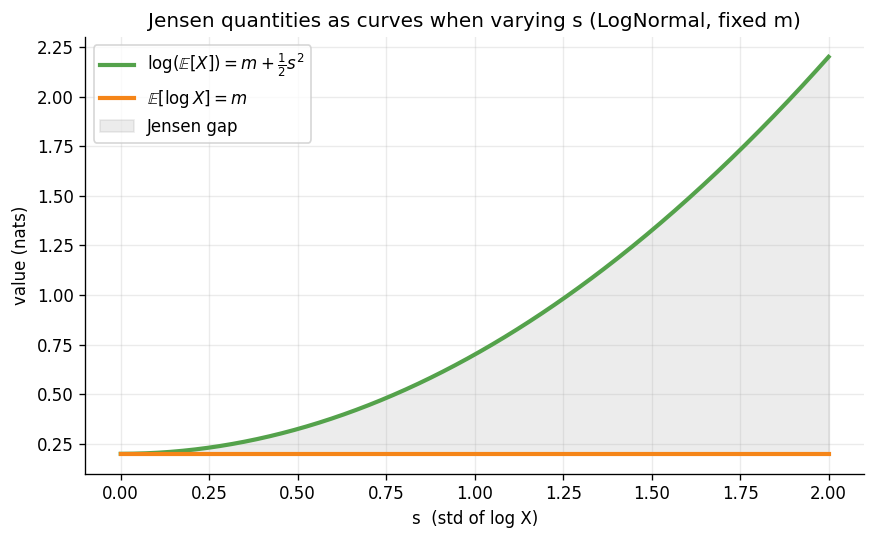

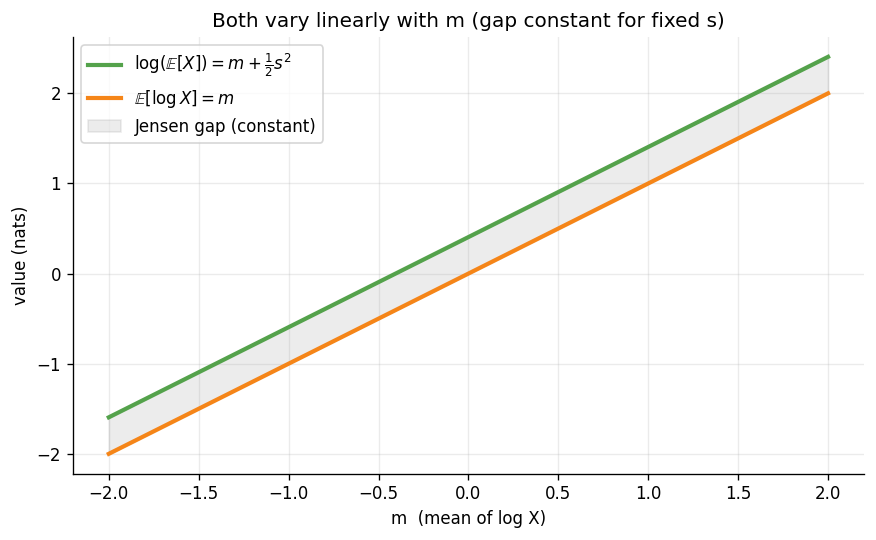

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Non-2-point distribution ----------
# X ~ LogNormal(m, s^2), continuous on (0, infinity)
rng = np.random.default_rng(0)
m = 0.2
s = 0.9
N = 200_000

X = rng.lognormal(mean=m, sigma=s, size=N)

Ex = X.mean()
Elog = np.log(X).mean()
logE = np.log(Ex)

# ---------- Plot 1: show them as points (fixed distribution) ----------
xgrid = np.linspace(0.05, 4.0, 600)
ygrid = np.log(xgrid)

# Tangent at x0 = E[X] (universal Jensen picture for concave log)
tangent = np.log(Ex) + (1/Ex) * (xgrid - Ex)

plt.figure(figsize=(7.4, 4.6))
plt.plot(xgrid, ygrid, color='black', lw=2, label='log(x) (concave)')
plt.plot(xgrid, tangent, color='#4C78A8', lw=2, linestyle='--',
         label='Tangent at x0 = E[X]')
plt.scatter([Ex], [Elog], color='#F58518', s=70, label='E[log X] (point)')
plt.scatter([Ex], [logE], color='#54A24B', s=70, label='log(E[X]) (point)')
plt.vlines(Ex, Elog, logE, color='gray', linestyle=':', lw=2)

plt.title('Jensen for log with a continuous X: points at x = E[X]')
plt.xlabel('x')
plt.ylabel('log(x)')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print("E[X]       =", Ex)
print("E[log X]   =", Elog)
print("log(E[X])  =", logE)
print("gap        =", logE - Elog)

# ---------- Plot 2: treat them as curves by varying s (distribution changes) ----------
s_grid = np.linspace(0.0, 2.0, 401)
Elog_curve = np.full_like(s_grid, m)          # E[log X] = m
logE_curve = m + 0.5 * s_grid**2              # log(E[X]) = m + s^2/2

plt.figure(figsize=(7.4, 4.6))
plt.plot(s_grid, logE_curve, lw=2.5, color='#54A24B',
         label=r'$\log(\mathbb{E}[X]) = m + \frac{1}{2}s^2$')
plt.plot(s_grid, Elog_curve, lw=2.5, color='#F58518',
         label=r'$\mathbb{E}[\log X] = m$')
plt.fill_between(s_grid, Elog_curve, logE_curve, color='gray', alpha=0.15,
                 label='Jensen gap')

plt.title('Jensen quantities as curves when varying s (LogNormal, fixed m)')
plt.xlabel('s  (std of log X)')
plt.ylabel('value (nats)')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# ---------- Plot 3 (optional): curves vs m with fixed s ----------
m_grid = np.linspace(-2, 2, 401)
Elog_m = m_grid
logE_m = m_grid + 0.5 * s**2

plt.figure(figsize=(7.4, 4.6))
plt.plot(m_grid, logE_m, lw=2.5, color='#54A24B',
         label=r'$\log(\mathbb{E}[X]) = m + \frac{1}{2}s^2$')
plt.plot(m_grid, Elog_m, lw=2.5, color='#F58518',
         label=r'$\mathbb{E}[\log X] = m$')
plt.fill_between(m_grid, Elog_m, logE_m, color='gray', alpha=0.15,
                 label='Jensen gap (constant)')

plt.title('Both vary linearly with m (gap constant for fixed s)')
plt.xlabel('m  (mean of log X)')
plt.ylabel('value (nats)')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## 2) ELBO derivation (symbolic steps)

Start:
$\log p(x)=\log\int p(x,z)dz.$

Insert any $q(z)$:
$\log p(x)=\log\int q(z)\frac{p(x,z)}{q(z)}dz = \log\mathbb{E}_q\left[\frac{p(x,z)}{q(z)}\right].$

Apply Jensen:
$\log p(x) \ge \mathbb{E}_q[\log p(x,z) - \log q(z)] \equiv \mathcal{L}(q).$

The gap is:
$\log p(x)-\mathcal{L}(q)=\mathrm{KL}(q(z)\|p(z\mid x)).$



## 3) Mean-field approximation

Mean-field assumes independence:
$ q(z)=\prod_{i=1}^m q_i(z_i). $

Why it matters:
- breaks high-dimensional expectations into smaller ones
- leads to coordinate ascent updates in conjugate models

Coordinate ascent update:
$ \log q_i^*(z_i)=\mathbb{E}_{q_{-i}}[\log p(x,z)] + \text{const}. $



## 4) Example: correlated Gaussian posterior vs mean-field

Let the true posterior be a correlated 2D Gaussian:
$p(z)=\mathcal{N}(0,\Sigma),\quad \Sigma=\begin{pmatrix}1 & \rho\sigma_1\sigma_2\\ \rho\sigma_1\sigma_2 & \sigma_2^2\end{pmatrix}.
$

Mean-field Gaussian restricts covariance to diagonal:
$q(z)=\mathcal{N}(0,\mathrm{diag}(\sigma_1^2,\sigma_2^2)).$

We plot contours to see what mean-field cannot represent.


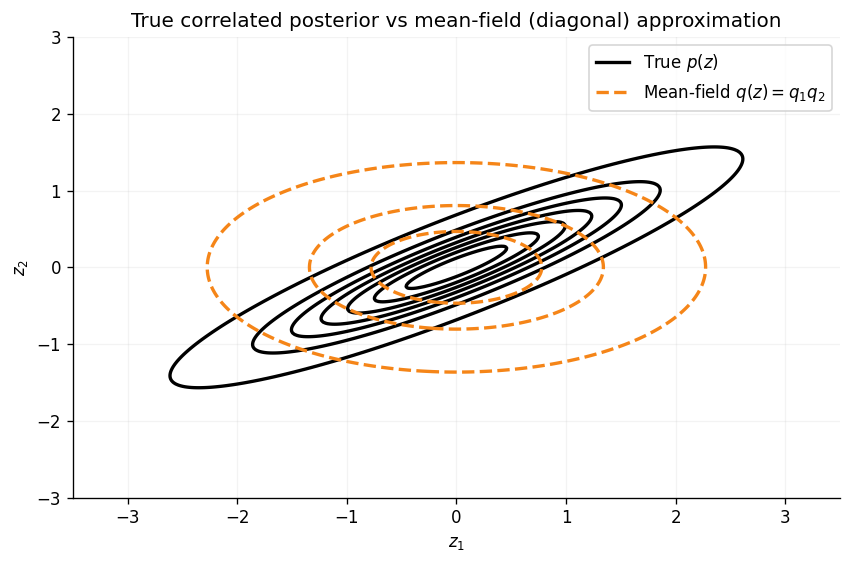

In [ ]:

mu = np.array([0.0, 0.0])
rho = 0.9
sig1, sig2 = 1.0, 0.6
Sigma = np.array([[sig1**2, rho*sig1*sig2], [rho*sig1*sig2, sig2**2]])
Sigma_q = np.diag([sig1**2, sig2**2])

xx = np.linspace(-3.5, 3.5, 350)
yy = np.linspace(-3.0, 3.0, 300)
X, Y = np.meshgrid(xx, yy)
Pos = np.dstack((X, Y))

def gaussian_pdf(pos, mean, cov):
    inv = np.linalg.inv(cov)
    det = np.linalg.det(cov)
    diff = pos - mean
    expo = np.einsum('...i,ij,...j->...', diff, inv, diff)
    return np.exp(-0.5*expo)/np.sqrt((2*np.pi)**2 * det)

P = gaussian_pdf(Pos, mu, Sigma)
Q = gaussian_pdf(Pos, mu, Sigma_q)
levels = np.linspace(0.02, P.max()*0.9, 7)

plt.figure(figsize=(7.2,4.8))
plt.contour(X, Y, P, levels=levels, colors='black', linewidths=2)
plt.contour(X, Y, Q, levels=levels, colors='#F58518', linestyles='--', linewidths=2)
plt.title('True correlated posterior vs mean-field (diagonal) approximation')
plt.xlabel('$z_1$'); plt.ylabel('$z_2$')
plt.grid(True, alpha=0.15)
plt.legend(handles=[
    plt.Line2D([0],[0], color='black', lw=2, label='True $p(z)$'),
    plt.Line2D([0],[0], color='#F58518', lw=2, linestyle='--', label='Mean-field $q(z)=q_1q_2$')
], loc='upper right')
plt.tight_layout()
plt.savefig('vi_mean_field_assets/figures/gaussian_contours_meanfield.png')
plt.show()


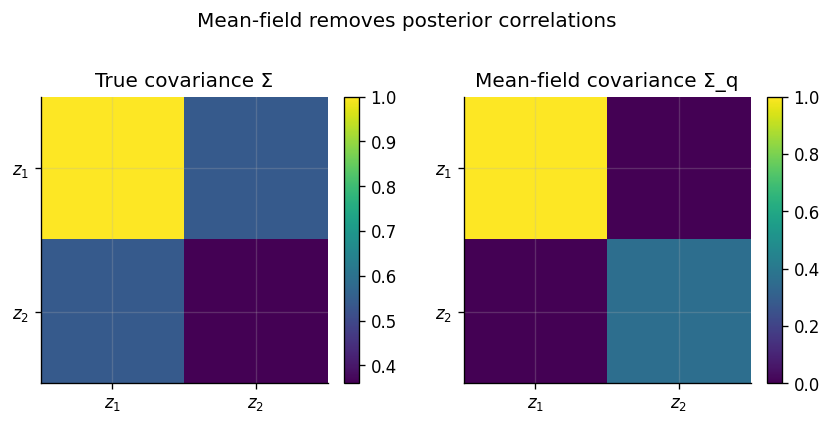

In [ ]:

# Covariance heatmaps
plt.figure(figsize=(7.2,3.4))
plt.subplot(1,2,1)
plt.imshow(Sigma, cmap='viridis')
plt.colorbar(fraction=0.046)
plt.title('True covariance Σ')
plt.xticks([0,1], ['$z_1$','$z_2$'])
plt.yticks([0,1], ['$z_1$','$z_2$'])

plt.subplot(1,2,2)
plt.imshow(Sigma_q, cmap='viridis')
plt.colorbar(fraction=0.046)
plt.title('Mean-field covariance Σ_q')
plt.xticks([0,1], ['$z_1$','$z_2$'])
plt.yticks([0,1], ['$z_1$','$z_2$'])

plt.suptitle('Mean-field removes posterior correlations')
plt.tight_layout(rect=[0,0,1,0.92])
plt.savefig('vi_mean_field_assets/figures/covariance_heatmaps.png')
plt.show()



## 5) Quantify the approximation error: KL(q||p)

For Gaussians with equal means:
$\mathrm{KL}(\mathcal{N}(0,\Sigma_q)\|\mathcal{N}(0,\Sigma))
=\tfrac12\Big(\mathrm{tr}(\Sigma^{-1}\Sigma_q)-k + \log\tfrac{\det\Sigma}{\det\Sigma_q}\Big).$

We compare:
- full-covariance Gaussian (can match exactly → KL=0)
- mean-field diagonal Gaussian
- diagonal but too-narrow Gaussian (collapsed)


KL(full||true)= 0.0
KL(mean-field||true)= 3.4327922913260194
KL(narrow diag||true)= 1.0622927783977945


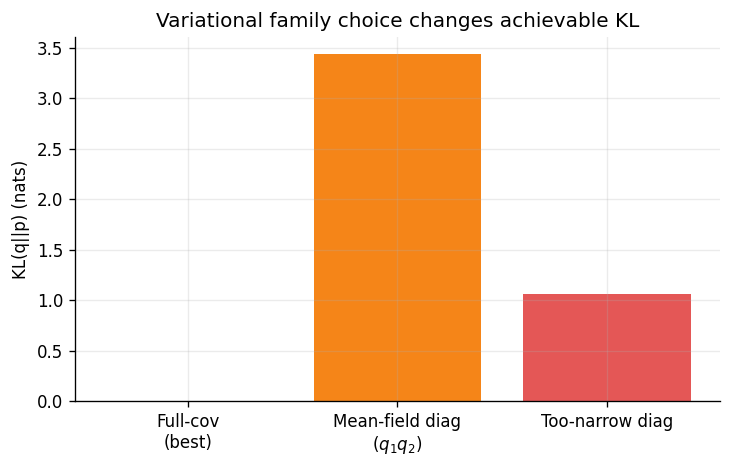

In [ ]:

def kl_gauss(Sq, S):
    k = S.shape[0]
    invS = np.linalg.inv(S)
    return 0.5*(np.trace(invS@Sq) - k + np.log(np.linalg.det(S)/np.linalg.det(Sq)))

Sigma_q_mf = Sigma_q
Sigma_q_full = Sigma
Sigma_q_narrow = np.diag([0.6**2, 0.35**2])

kl_full = kl_gauss(Sigma_q_full, Sigma)
kl_mf = kl_gauss(Sigma_q_mf, Sigma)
kl_narrow = kl_gauss(Sigma_q_narrow, Sigma)

print('KL(full||true)=', kl_full)
print('KL(mean-field||true)=', kl_mf)
print('KL(narrow diag||true)=', kl_narrow)

plt.figure(figsize=(6.2,4))
vals = [kl_full, kl_mf, kl_narrow]
labels = ['Full-cov\n(best)', 'Mean-field diag\n($q_1q_2$)', 'Too-narrow diag']
colors = ['#54A24B', '#F58518', '#E45756']
plt.bar(range(len(vals)), vals, color=colors)
plt.xticks(range(len(vals)), labels)
plt.ylabel('KL(q||p) (nats)')
plt.title('Variational family choice changes achievable KL')
plt.grid(True, axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('vi_mean_field_assets/figures/kl_bar_variational_family.png')
plt.show()


# ELBO: The Heart of Variational Inference

This notebook provides:

1. A clean derivation of the ELBO starting from
   $\mathrm{KL}(q(z)\|p(z\mid x))$.
2. The key identity:
   $\mathrm{KL}(q\|p(z\mid x)) = \log p(x) - \mathcal{L}(q).$
3. The standard ELBO decomposition:
   $\mathcal{L}(q)=\mathbb{E}_q[\log p(x\mid z)]-\mathrm{KL}(q(z)\|p(z)).$
4. A fully worked 1D Gaussian latent-variable example with analytic formulas and plots.

Figures are saved to `vi_elbo_assets/figures/`.


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('vi_elbo_assets/figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 120


## 1) Deriving the ELBO from KL(q‖posterior)

Start:  
$ \mathrm{KL}(q(z)\|p(z\mid x)) = \mathbb{E}_q[\log q(z) - \log p(z\mid x)] $.

Use Bayes:  
$ \log p(z\mid x) = \log p(x,z) - \log p(x) $.

Then:  
$ \mathrm{KL}(q\|p(z\mid x)) = \log p(x) - \mathbb{E}_q[\log p(x,z) - \log q(z)] $.

Define ELBO:  
$ \mathcal{L}(q) = \mathbb{E}_q[\log p(x,z)] - \mathbb{E}_q[\log q(z)] $.

So:  
$ \mathrm{KL}(q\|p(z\mid x)) = \log p(x) - \mathcal{L}(q) $.



## 2) ELBO interpretation

For latent models $ p(x,z) = p(x\mid z)p(z) $:

$ \mathcal{L}(q) = \mathbb{E}_q[\log p(x\mid z)] - \mathrm{KL}(q(z)\|p(z)) $.

- $ \mathbb{E}_q[\log p(x\mid z)] $: **accuracy / reconstruction**
- $ \mathrm{KL}(q\|p(z)) $: **complexity** penalty for deviating from the prior



## 3) Worked example: conjugate Gaussian model

Model:
- Prior: $ z \sim \mathcal{N}(0,1) $
- Likelihood: $ x \mid z \sim \mathcal{N}(z,\sigma_x^2) $

Variational family:
- $ q(z) = \mathcal{N}(\mu,\sigma^2) $

Because the model is conjugate, the true posterior is Gaussian and we can compute:
- $ \log p(x) $ exactly
- ELBO exactly
- $ \mathrm{KL}(q\|p(z\mid x)) $ exactly

We then verify numerically that:
$ \log p(x) - \mathcal{L}(q) = \mathrm{KL}(q\|p(z\mid x)) $.

In [ ]:

# Observed data and noise
x_obs = 1.5
sigma_x = 0.7

# True posterior parameters
post_var = 1 / (1 + 1/(sigma_x**2))
post_mean = post_var * (x_obs/(sigma_x**2))
post_std = np.sqrt(post_var)

# Evidence p(x) = N(0, 1+sigma_x^2)
log_px = -0.5*np.log(2*np.pi*(1+sigma_x**2)) - 0.5*(x_obs**2)/(1+sigma_x**2)

print('Posterior mean:', post_mean)
print('Posterior std :', post_std)
print('log p(x)      :', log_px)


Posterior mean: 1.0067114093959733
Posterior std : 0.5734623443633283
log p(x)      : -1.8733601502303365


In [ ]:

# ELBO and KL formulas

def elbo(mu, s):
    # ELBO = E_q[log p(x|z)] - KL(q||p(z))
    recon = -0.5*np.log(2*np.pi*(sigma_x**2)) - 0.5*((x_obs-mu)**2 + s**2)/(sigma_x**2)
    kl_q_prior = 0.5*(mu**2 + s**2 - 1 - np.log(s**2))
    return recon - kl_q_prior, recon, kl_q_prior

def kl_q_posterior(mu, s):
    return 0.5*( (s**2)/post_var + ((mu-post_mean)**2)/post_var - 1 + np.log(post_var/(s**2)) )

# Check the identity at a random q
mu_test, s_test = 0.2, 1.1
L, recon, klprior = elbo(mu_test, s_test)
klpost = kl_q_posterior(mu_test, s_test)

print('log p(x) - ELBO    =', log_px - L)
print('KL(q||posterior)   =', klpost)
print('difference         =', (log_px - L) - klpost)


log p(x) - ELBO    = 1.6777769327006675
KL(q||posterior)   = 1.6777769327006675
difference         = 0.0


/tmp/ipykernel_2920/698515933.py:14: UserWarning: Glyph 120027 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL L}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2920/698515933.py:15: UserWarning: Glyph 120027 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL L}) missing from font(s) DejaVu Sans.
  plt.savefig('vi_elbo_assets/figures/elbo_vs_mu.png')
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 120027 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL L}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


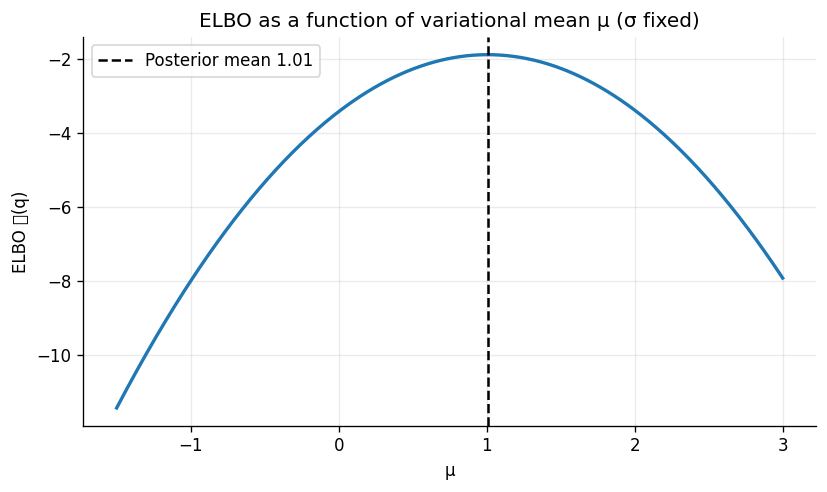

In [ ]:

# Plot 1: ELBO vs mu (sigma fixed)
s_fixed = post_std
mu_grid = np.linspace(-1.5, 3.0, 400)
L_mu = np.array([elbo(m, s_fixed)[0] for m in mu_grid])

plt.figure(figsize=(7.0,4.2))
plt.plot(mu_grid, L_mu, lw=2)
plt.axvline(post_mean, color='k', linestyle='--', label=f'Posterior mean {post_mean:.2f}')
plt.title('ELBO as a function of variational mean μ (σ fixed)')
plt.xlabel('μ')
plt.ylabel('ELBO 𝓛(q)')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_elbo_assets/figures/elbo_vs_mu.png')
plt.show()


/tmp/ipykernel_2920/2601166058.py:14: UserWarning: Glyph 120027 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL L}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2920/2601166058.py:15: UserWarning: Glyph 120027 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL L}) missing from font(s) DejaVu Sans.
  plt.savefig('vi_elbo_assets/figures/elbo_vs_sigma.png')


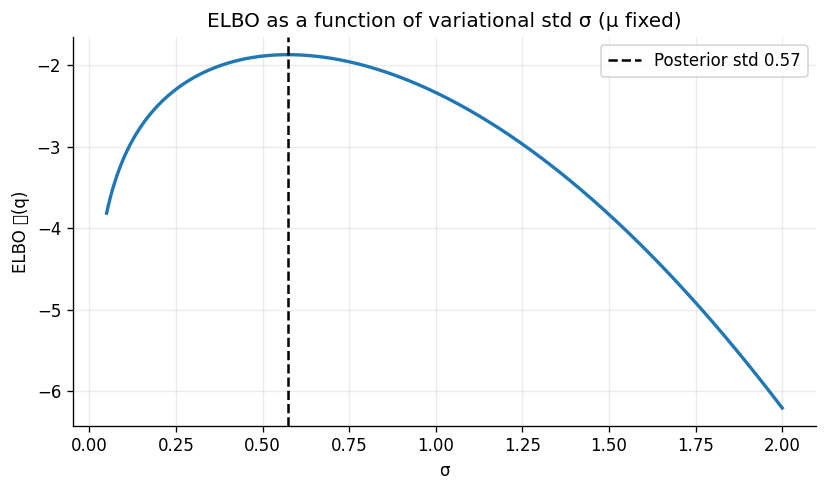

In [ ]:

# Plot 2: ELBO vs sigma (mu fixed)
mu_fixed = post_mean
s_grid = np.linspace(0.05, 2.0, 400)
L_s = np.array([elbo(mu_fixed, s)[0] for s in s_grid])

plt.figure(figsize=(7.0,4.2))
plt.plot(s_grid, L_s, lw=2)
plt.axvline(post_std, color='k', linestyle='--', label=f'Posterior std {post_std:.2f}')
plt.title('ELBO as a function of variational std σ (μ fixed)')
plt.xlabel('σ')
plt.ylabel('ELBO 𝓛(q)')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_elbo_assets/figures/elbo_vs_sigma.png')
plt.show()


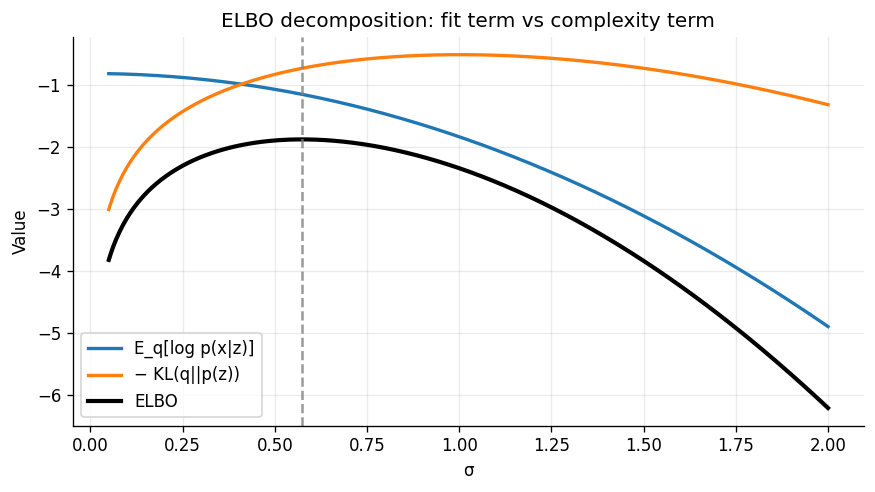

In [ ]:

# Plot 3: ELBO decomposition: recon vs -KL to prior
recon_s = np.array([elbo(mu_fixed, s)[1] for s in s_grid])
klprior_s = np.array([elbo(mu_fixed, s)[2] for s in s_grid])

plt.figure(figsize=(7.4,4.2))
plt.plot(s_grid, recon_s, lw=2, label='E_q[log p(x|z)]')
plt.plot(s_grid, -klprior_s, lw=2, label='− KL(q||p(z))')
plt.plot(s_grid, recon_s - klprior_s, lw=2.5, label='ELBO', color='black')
plt.axvline(post_std, color='gray', linestyle='--', alpha=0.8)
plt.title('ELBO decomposition: fit term vs complexity term')
plt.xlabel('σ')
plt.ylabel('Value')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_elbo_assets/figures/elbo_decomposition.png')
plt.show()


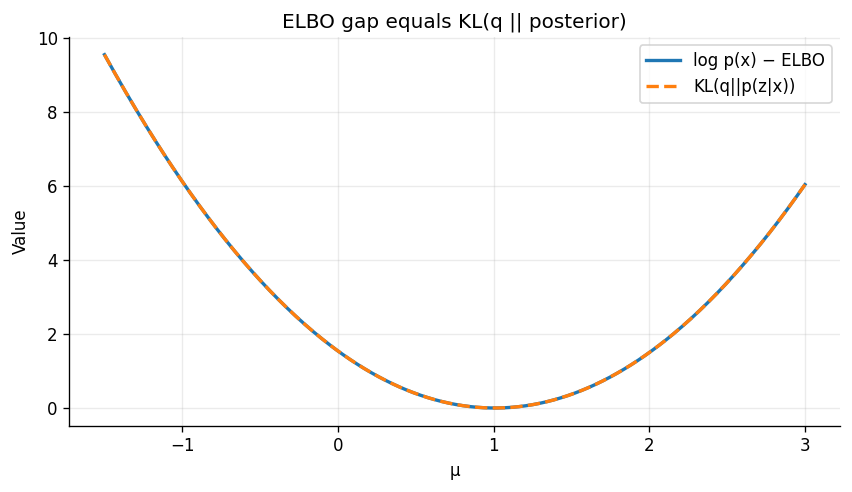

In [ ]:

# Plot 4: ELBO gap equals KL(q||posterior)
KL_post_mu = np.array([kl_q_posterior(m, s_fixed) for m in mu_grid])
Gap_mu = log_px - L_mu

plt.figure(figsize=(7.2,4.2))
plt.plot(mu_grid, Gap_mu, lw=2, label='log p(x) − ELBO')
plt.plot(mu_grid, KL_post_mu, lw=2, linestyle='--', label='KL(q||p(z|x))')
plt.title('ELBO gap equals KL(q || posterior)')
plt.xlabel('μ')
plt.ylabel('Value')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_elbo_assets/figures/elbo_gap_equals_kl.png')
plt.show()


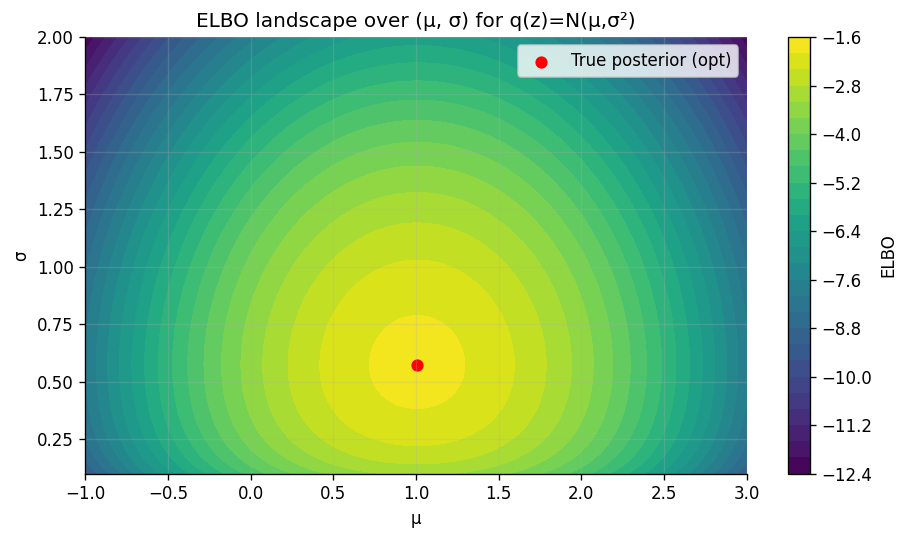

In [ ]:

# Plot 5: ELBO surface over (mu, sigma)
MU, SG = np.meshgrid(np.linspace(-1.0, 3.0, 140), np.linspace(0.1, 2.0, 140))
L_surf = np.zeros_like(MU)
for i in range(MU.shape[0]):
    for j in range(MU.shape[1]):
        L_surf[i,j] = elbo(MU[i,j], SG[i,j])[0]

plt.figure(figsize=(7.8,4.6))
cs = plt.contourf(MU, SG, L_surf, levels=30, cmap='viridis')
plt.colorbar(cs, label='ELBO')
plt.scatter([post_mean], [post_std], color='red', s=40, label='True posterior (opt)')
plt.title('ELBO landscape over (μ, σ) for q(z)=N(μ,σ²)')
plt.xlabel('μ')
plt.ylabel('σ')
plt.legend()
plt.tight_layout()
plt.savefig('vi_elbo_assets/figures/elbo_surface.png')
plt.show()



# Reparameterization Trick and REINFORCE (Score-function Estimator)

This notebook supports the slides and provides:

- Theory + intuition for **reparameterization**: $z=\mu+\sigma\epsilon$
- Theory + intuition for **REINFORCE**: $\mathbb{E}[f(z)\nabla\log q(z)]$
- Why REINFORCE can have high variance and how **baselines/control variates** help
- Empirical variance comparisons with graphs

All figures are saved to `vi_reparam_assets/figures/`.


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('vi_reparam_assets/figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 120


## Continuous toy objective: full derivations

### Objective
Let
$
J(\mu)=\mathbb{E}_{z\sim\mathcal N(\mu,1)}\big[(z-3)^2\big].
$
Define
$
f(z) := (z-3)^2,\qquad p_\mu(z):=\mathcal N(z;\mu,1).
$

---

## 1) Closed-form expression for $J(\mu)$ and its gradient

### Step 1: Rewrite $z$ as a shift of a standard normal
Let
$
z=\mu+\eta,\qquad \eta\sim\mathcal N(0,1).
$
Then
$
J(\mu)=\mathbb{E}_{\eta\sim\mathcal N(0,1)}\big[(\mu+\eta-3)^2\big].
$

### Step 2: Expand the square
$
(\mu+\eta-3)^2 = (\mu-3)^2 + 2(\mu-3)\eta + \eta^2.
$

### Step 3: Take expectations using $\mathbb{E}[\eta]=0$ and $\mathbb{E}[\eta^2]=1$
$
J(\mu) = (\mu-3)^2 + 2(\mu-3)\mathbb{E}[\eta] + \mathbb{E}[\eta^2]
       = (\mu-3)^2 + 1.
$

### Step 4: Differentiate
$
\nabla_\mu J(\mu)=\frac{d}{d\mu}\big((\mu-3)^2+1\big)=2(\mu-3).
$

---

## 2) Reparameterization (pathwise) gradient estimator

### Step 1: Reparameterize the sampling
Sample
$
\varepsilon\sim\mathcal N(0,1),\qquad z=\mu+\varepsilon.
$
Then
$
J(\mu)=\mathbb{E}_{\varepsilon}\big[(\mu+\varepsilon-3)^2\big].
$

### Step 2: Differentiate inside the expectation (pathwise derivative)
Let
$
g(\mu,\varepsilon) := (\mu+\varepsilon-3)^2.
$
Then
$
\nabla_\mu J(\mu) = \nabla_\mu \mathbb{E}_{\varepsilon}[g(\mu,\varepsilon)]
                  = \mathbb{E}_{\varepsilon}\big[\nabla_\mu g(\mu,\varepsilon)\big].
$

### Step 3: Compute $\nabla_\mu g(\mu,\varepsilon)$
$
\nabla_\mu g(\mu,\varepsilon)=2(\mu+\varepsilon-3).
$
Since $z=\mu+\varepsilon$,
$
\nabla_\mu g(\mu,\varepsilon)=2(z-3).
$

### Monte Carlo estimator
Draw $\varepsilon\sim\mathcal N(0,1)$, set $z=\mu+\varepsilon$, and use
$
\boxed{ \; \hat g_{\text{reparam}} = 2(z-3)\; }.
$

### (Optional) Expectation check
$
\mathbb{E}[\hat g_{\text{reparam}}]
= \mathbb{E}_{\varepsilon}[2(\mu+\varepsilon-3)]
= 2(\mu-3) + 2\mathbb{E}[\varepsilon]
= 2(\mu-3).
$

---

## 3) Score-function / REINFORCE gradient estimator

### Step 1: Start from the expectation under $p_\mu$
$
J(\mu)=\int f(z)\,p_\mu(z)\,dz.
$

### Step 2: Differentiate w.r.t. $\mu$
$
\nabla_\mu J(\mu)=\nabla_\mu \int f(z)\,p_\mu(z)\,dz
= \int f(z)\,\nabla_\mu p_\mu(z)\,dz.
$

### Step 3: Use $\nabla_\mu p_\mu(z)=p_\mu(z)\,\nabla_\mu \log p_\mu(z)$
$
\nabla_\mu J(\mu) = \int f(z)\,p_\mu(z)\,\nabla_\mu \log p_\mu(z)\,dz
= \mathbb{E}_{z\sim p_\mu}\big[f(z)\,\nabla_\mu \log p_\mu(z)\big].
$

### Step 4: Compute the score $\nabla_\mu\log p_\mu(z)$ for $\mathcal N(\mu,1)$
For
$
p_\mu(z)=\frac{1}{\sqrt{2\pi}}\exp\!\left(-\tfrac12(z-\mu)^2\right),
$
$
\log p_\mu(z)= -\tfrac12(z-\mu)^2 - \tfrac12\log(2\pi),
$
so
$
\nabla_\mu \log p_\mu(z)= -\tfrac12\cdot 2(z-\mu)\cdot(-1) = (z-\mu).
$

### Step 5: Plug in $f(z)=(z-3)^2$
$
\nabla_\mu J(\mu)=\mathbb{E}_{z\sim\mathcal N(\mu,1)}\big[(z-3)^2(z-\mu)\big].
$

### Monte Carlo estimator
Sample $z\sim\mathcal N(\mu,1)$ and use
$
\boxed{\; \hat g_{\text{score}} = (z-3)^2(z-\mu)\; }.
$



In [ ]:

# Define functions

def f(z):
    return (z-3.0)**2

def grad_true(mu):
    return 2*(mu-3.0)

def grad_reparam(mu, S, rng):
    eps = rng.standard_normal(S)
    z = mu + eps
    g = 2*(z-3.0)
    return g.mean()

def grad_score(mu, S, rng, baseline=None):
    eps = rng.standard_normal(S)
    z = mu + eps
    score = (z-mu)
    vals = f(z)
    if baseline is None:
        g = vals*score
    else:
        g = (vals-baseline)*score
    return g.mean()

def baseline_opt(mu, rng, M=200000):
    eps = rng.standard_normal(M)
    z = mu + eps
    score = (z-mu)
    vals = f(z)
    cov = np.mean((vals-vals.mean())*(score-score.mean()))
    var = np.var(score)
    return cov/var

mu0 = 0.0
rng = np.random.default_rng(0)
b_opt = baseline_opt(mu0, rng, M=300000)
print('True grad:', grad_true(mu0))
print('Estimated optimal baseline b*:', b_opt)


True grad: -6.0
Estimated optimal baseline b*: -6.0046842491458605


## 2) Variance vs sample size (continuous)

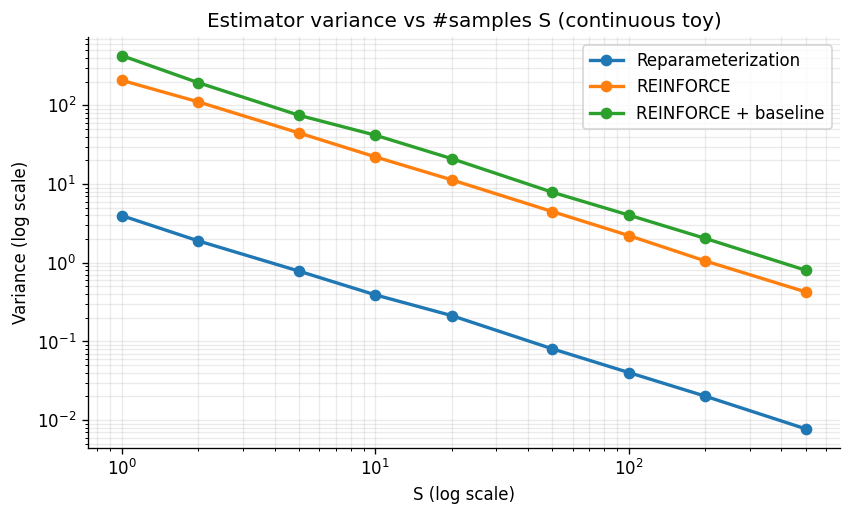

In [ ]:

S_grid = np.array([1,2,5,10,20,50,100,200,500])
R = 3000

rng = np.random.default_rng(1)
vars_reparam=[]
vars_score=[]
vars_score_b=[]

for S in S_grid:
    gr=[]; gs=[]; gsb=[]
    for _ in range(R):
        gr.append(grad_reparam(mu0, S, rng))
        gs.append(grad_score(mu0, S, rng, baseline=None))
        gsb.append(grad_score(mu0, S, rng, baseline=b_opt))
    vars_reparam.append(np.var(gr))
    vars_score.append(np.var(gs))
    vars_score_b.append(np.var(gsb))

plt.figure(figsize=(7.2,4.4))
plt.loglog(S_grid, vars_reparam, marker='o', lw=2, label='Reparameterization')
plt.loglog(S_grid, vars_score, marker='o', lw=2, label='REINFORCE')
plt.loglog(S_grid, vars_score_b, marker='o', lw=2, label='REINFORCE + baseline')
plt.title('Estimator variance vs #samples S (continuous toy)')
plt.xlabel('S (log scale)')
plt.ylabel('Variance (log scale)')
plt.grid(True, which='both', alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_reparam_assets/figures/variance_vs_S_continuous.png')
plt.show()


## 3) Histogram of estimates (continuous, S=10)

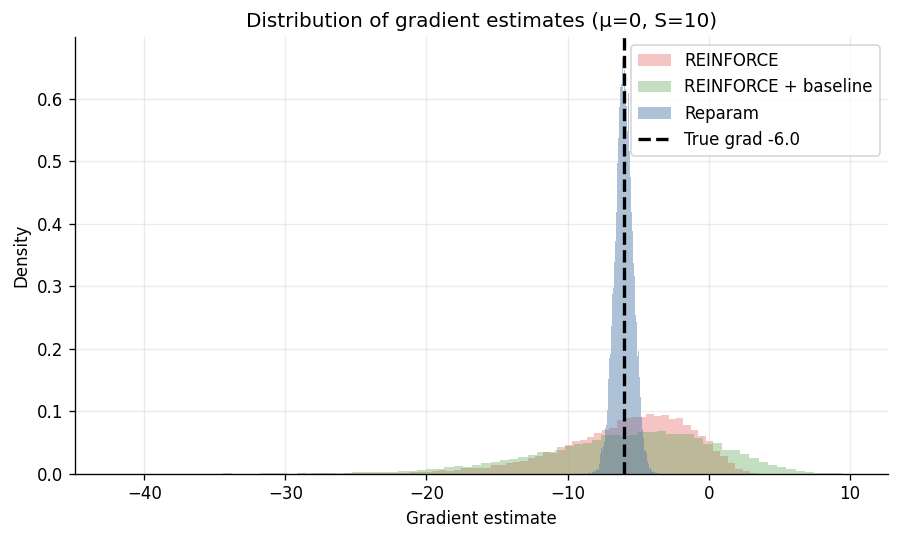

In [ ]:

S = 10
rng = np.random.default_rng(2)
reps = 20000
true_g = grad_true(mu0)

reparam = np.array([grad_reparam(mu0, S, rng) for _ in range(reps)])
score = np.array([grad_score(mu0, S, rng) for _ in range(reps)])
score_b = np.array([grad_score(mu0, S, rng, baseline=b_opt) for _ in range(reps)])

plt.figure(figsize=(7.6,4.6))
bins=80
plt.hist(score, bins=bins, density=True, alpha=0.35, label='REINFORCE', color='#E45756')
plt.hist(score_b, bins=bins, density=True, alpha=0.35, label='REINFORCE + baseline', color='#54A24B')
plt.hist(reparam, bins=bins, density=True, alpha=0.45, label='Reparam', color='#4C78A8')
plt.axvline(true_g, color='k', linestyle='--', lw=2, label=f'True grad {true_g:.1f}')
plt.title('Distribution of gradient estimates (μ=0, S=10)')
plt.xlabel('Gradient estimate')
plt.ylabel('Density')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_reparam_assets/figures/hist_grad_estimates.png')
plt.show()



## 4) Discrete example: Bernoulli + REINFORCE baseline

Let $z\sim\text{Bernoulli}(p)$ and objective $J(p)=\mathbb{E}[z]=p$.
If we parameterize with logit $\alpha$ where $p=\sigma(\alpha)$, the true gradient is
$\frac{dJ}{d\alpha}=p(1-p).$

REINFORCE gradient wrt $\alpha$:
$g=(f(z)-b)(z-p),\quad f(z)=z.$
A good baseline is $b\approx\mathbb{E}[z]=p$.


True grad dJ/dlogit: 0.16000000000000003


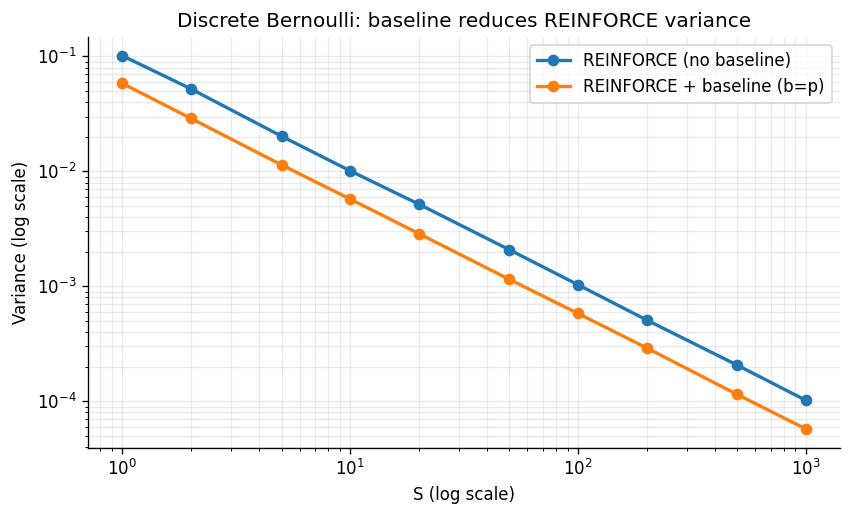

In [ ]:


def reinforce_bernoulli(p, S, rng, baseline=None):
    z = (rng.random(S) < p).astype(float)
    score = z - p
    fz = z
    if baseline is None:
        g = fz*score
    else:
        g = (fz-baseline)*score
    return g.mean()

p0 = 0.2
true_grad_logit = p0*(1-p0)
print('True grad dJ/dlogit:', true_grad_logit)

S_grid2 = np.array([1,2,5,10,20,50,100,200,500,1000])
R=20000
rng = np.random.default_rng(3)
vars_plain=[]
vars_base=[]

for S in S_grid2:
    g1=[]; g2=[]
    for _ in range(R):
        g1.append(reinforce_bernoulli(p0, S, rng, baseline=None))
        g2.append(reinforce_bernoulli(p0, S, rng, baseline=p0))
    vars_plain.append(np.var(g1))
    vars_base.append(np.var(g2))

plt.figure(figsize=(7.2,4.4))
plt.loglog(S_grid2, vars_plain, marker='o', lw=2, label='REINFORCE (no baseline)')
plt.loglog(S_grid2, vars_base, marker='o', lw=2, label='REINFORCE + baseline (b=p)')
plt.title('Discrete Bernoulli: baseline reduces REINFORCE variance')
plt.xlabel('S (log scale)')
plt.ylabel('Variance (log scale)')
plt.grid(True, which='both', alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('vi_reparam_assets/figures/bernoulli_reinforce_variance.png')
plt.show()



## 5) Key takeaway for VAEs

VAE ELBO:
$\mathcal{L}=\mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]-\mathrm{KL}(q_\phi(z\mid x)\|p(z)).$

Reparameterization:
$z=\mu_\phi(x)+\sigma_\phi(x)\odot\epsilon,\quad \epsilon\sim\mathcal{N}(0,I).$

This makes gradients w.r.t. $\phi$ flow through $z$, enabling minibatch SGD.


# Black-box SVI recipe (pathwise gradients + Adam)

This section puts the automated-VI loop of the slides together on a conjugate toy model, where the exact posterior is known so convergence can be checked:
- minibatch $B_t$ of size $k$ with the $N/k$ scaling of the log-likelihood,
- pathwise (reparameterization) gradients computed by PyTorch autograd,
- Adam, gradient clipping, and clamping of $\log\sigma$ for stability (the $N/k$ scaling makes gradients large).

Figures are saved into `vi_svi_recipe_assets_fixed/figures/`.


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import torch

os.makedirs('vi_svi_recipe_assets_fixed/figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 120

# Data
rng = np.random.default_rng(42)
N = 50000
true_theta = 1.2
sigma = 1.0
x = rng.normal(true_theta, sigma, size=N).astype(np.float32)

# Prior
mu0 = 0.0
lambda0 = 1.0

# Exact posterior (validation)
post_lambda = lambda0 + N/(sigma**2)
post_mu = (lambda0*mu0 + np.sum(x)/(sigma**2)) / post_lambda
post_var = 1/post_lambda
post_std = float(np.sqrt(post_var))

print('Posterior mean:', post_mu)
print('Posterior std :', post_std)


Posterior mean: 1.1994457
Posterior std : 0.004472091234310839


## Black-box SVI (reparameterization + Adam)

We maximize the (scaled) minibatch ELBO estimate:
$\widehat{\mathcal{L}} = \mathbb{E}_q[\log p(\theta)] + \frac{N}{k}\sum_{n\in B_t}\mathbb{E}_q[\log p(x_n\mid\theta)] - \mathbb{E}_q[\log q(\theta)].$

Stability tricks: Adam, gradient clipping, and clamping $\log\sigma$. In the code, `batch_size` is $k$.


In [ ]:


def blackbox_svi_torch(x, batch_size=512, S=8, iters=1500, lr=5e-3, seed=0, clip=10.0):
    torch.manual_seed(seed)
    x_t = torch.tensor(x)
    N = x_t.shape[0]

    mu = torch.zeros((), requires_grad=True)
    log_sigma = torch.zeros((), requires_grad=True)

    opt = torch.optim.Adam([mu, log_sigma], lr=lr)

    mu_hist=[]; sig_hist=[]; elbo_hist=[]

    for t in range(iters):
        idx = torch.randint(0, N, (batch_size,))
        xb = x_t[idx]

        eps = torch.randn(S)
        sigma_q = torch.exp(log_sigma).clamp(min=1e-6)
        theta = mu + sigma_q*eps

        logp_theta = 0.5*torch.log(torch.tensor(lambda0)) - 0.5*lambda0*(theta-mu0)**2
        ll = -0.5*N*torch.log(torch.tensor(sigma**2)) - 0.5*(N/batch_size)*torch.sum((xb[None,:]-theta[:,None])**2, dim=1)/(sigma**2)
        logq = -log_sigma - 0.5*((theta-mu)/sigma_q)**2

        elbo = torch.mean(logp_theta + ll - logq)
        loss = -elbo

        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_([mu, log_sigma], max_norm=clip)
        opt.step()

        with torch.no_grad():
            log_sigma.clamp_(min=-12.0, max=2.0)

        mu_hist.append(mu.item())
        sig_hist.append(torch.exp(log_sigma).item())
        elbo_hist.append(elbo.item())

    return np.array(mu_hist), np.array(sig_hist), np.array(elbo_hist)

mu_bb, sig_bb, elbo_bb = blackbox_svi_torch(x)
print('Final mu:', mu_bb[-1], 'Final sigma:', sig_bb[-1])


Final mu: 1.193966269493103 Final sigma: 0.024697061628103256


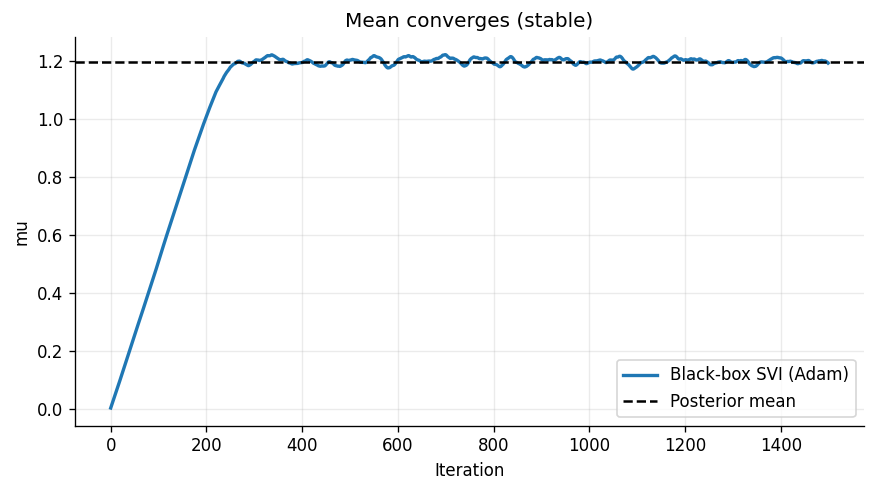

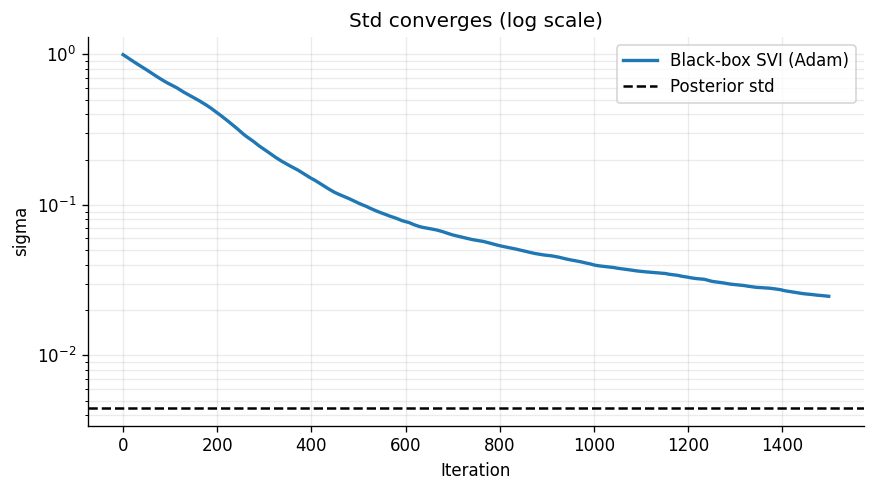

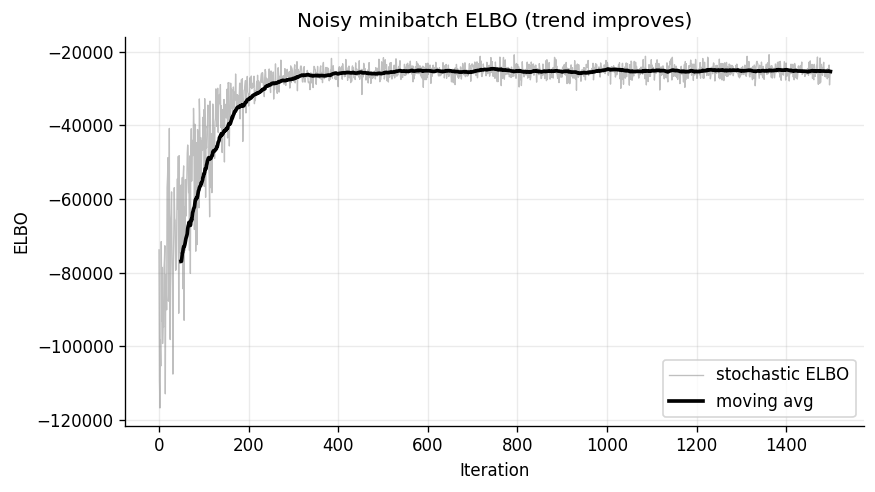

In [ ]:

# Plots
window = 50
ma = np.convolve(elbo_bb, np.ones(window)/window, mode='valid')

plt.figure(figsize=(7.4,4.2))
plt.plot(mu_bb, lw=2, label='Black-box SVI (Adam)')
plt.axhline(post_mu, color='k', linestyle='--', label='Posterior mean')
plt.title('Mean converges (stable)')
plt.xlabel('Iteration'); plt.ylabel('mu')
plt.grid(True, alpha=0.25); plt.legend(); plt.tight_layout()
plt.savefig('vi_svi_recipe_assets_fixed/figures/bb_svi_mu.png')
plt.show()

plt.figure(figsize=(7.4,4.2))
plt.plot(sig_bb, lw=2, label='Black-box SVI (Adam)')
plt.axhline(post_std, color='k', linestyle='--', label='Posterior std')
plt.yscale('log')
plt.title('Std converges (log scale)')
plt.xlabel('Iteration'); plt.ylabel('sigma')
plt.grid(True, which='both', alpha=0.25); plt.legend(); plt.tight_layout()
plt.savefig('vi_svi_recipe_assets_fixed/figures/bb_svi_sigma.png')
plt.show()

plt.figure(figsize=(7.4,4.2))
plt.plot(elbo_bb, lw=0.8, color='gray', alpha=0.5, label='stochastic ELBO')
plt.plot(np.arange(window-1, window-1+len(ma)), ma, lw=2.2, color='black', label='moving avg')
plt.title('Noisy minibatch ELBO (trend improves)')
plt.xlabel('Iteration'); plt.ylabel('ELBO')
plt.grid(True, alpha=0.25); plt.legend(); plt.tight_layout()
plt.savefig('vi_svi_recipe_assets_fixed/figures/bb_svi_elbo.png')
plt.show()
